# RV timeseries preview

This read-only notebook selects a reproducible random sample of generated systems. Each figure shows the shared photometry and every stored RV realisation for that system. RV colour denotes requested accuracy and marker denotes the number of observations.

In [1]:
import sys
from pathlib import Path

import numpy as np
from astropy.io import fits
from matplotlib import colors, lines
from matplotlib import pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / 'src'))

from rv_timeseries import rv_paths

SAMPLE_SIZE = 5
RANDOM_SEED = 20260827

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.25})

2026-08-27 11:22:44,396 DEBUG [utils] Logging configured at DEBUG
2026-08-27 11:22:44,399 DEBUG [utils] Data path initialised at /scratch/anm1u24/self_lensing_radial_velocity/data


Previewing 5 of 6433 generated systems


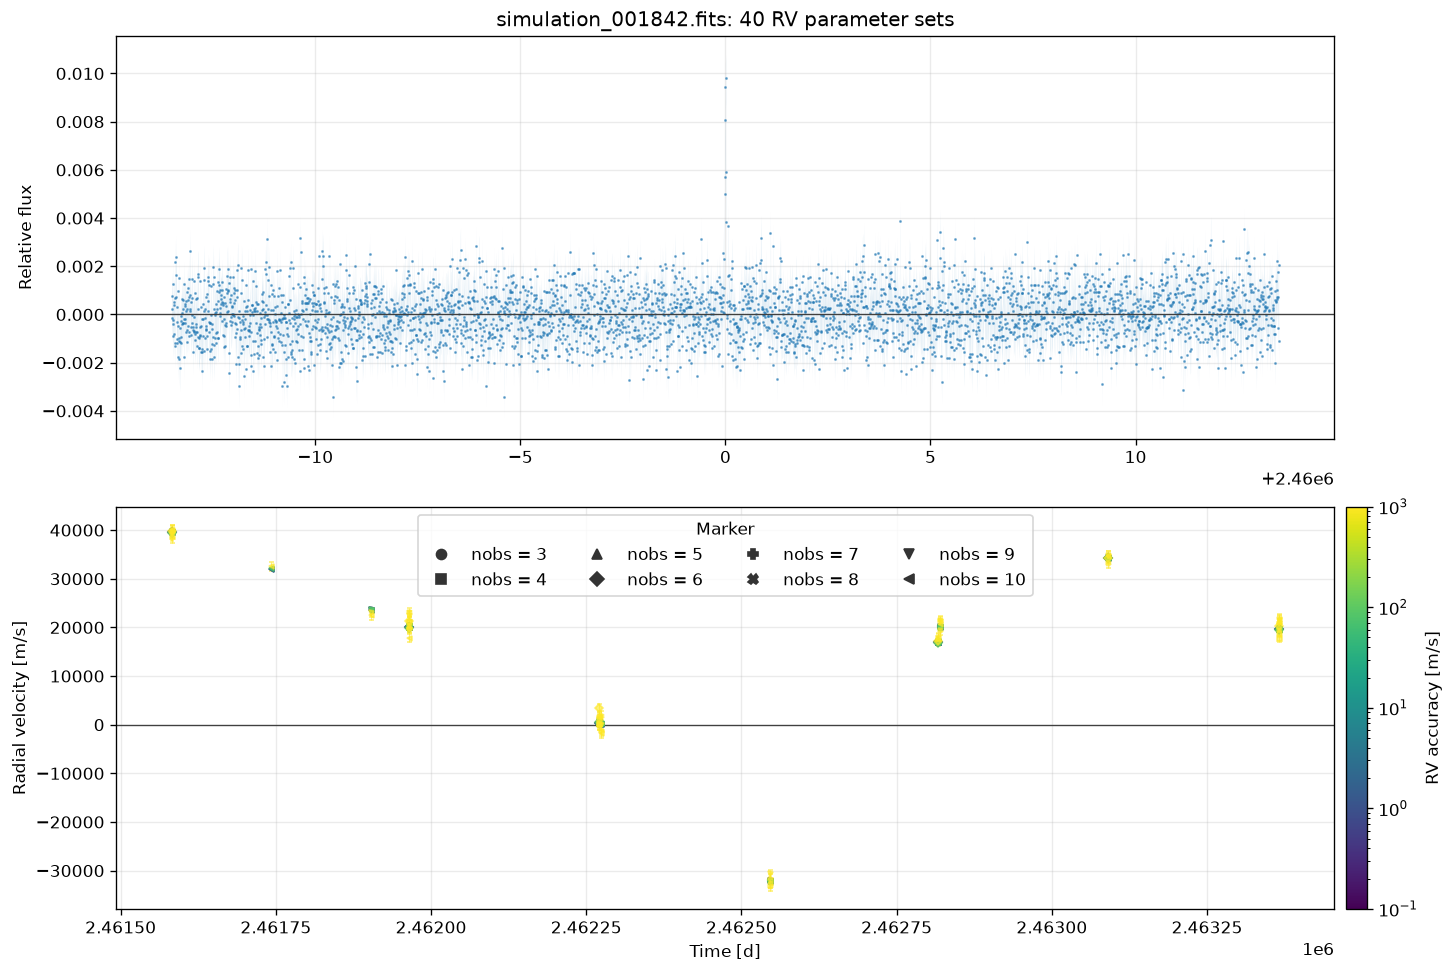

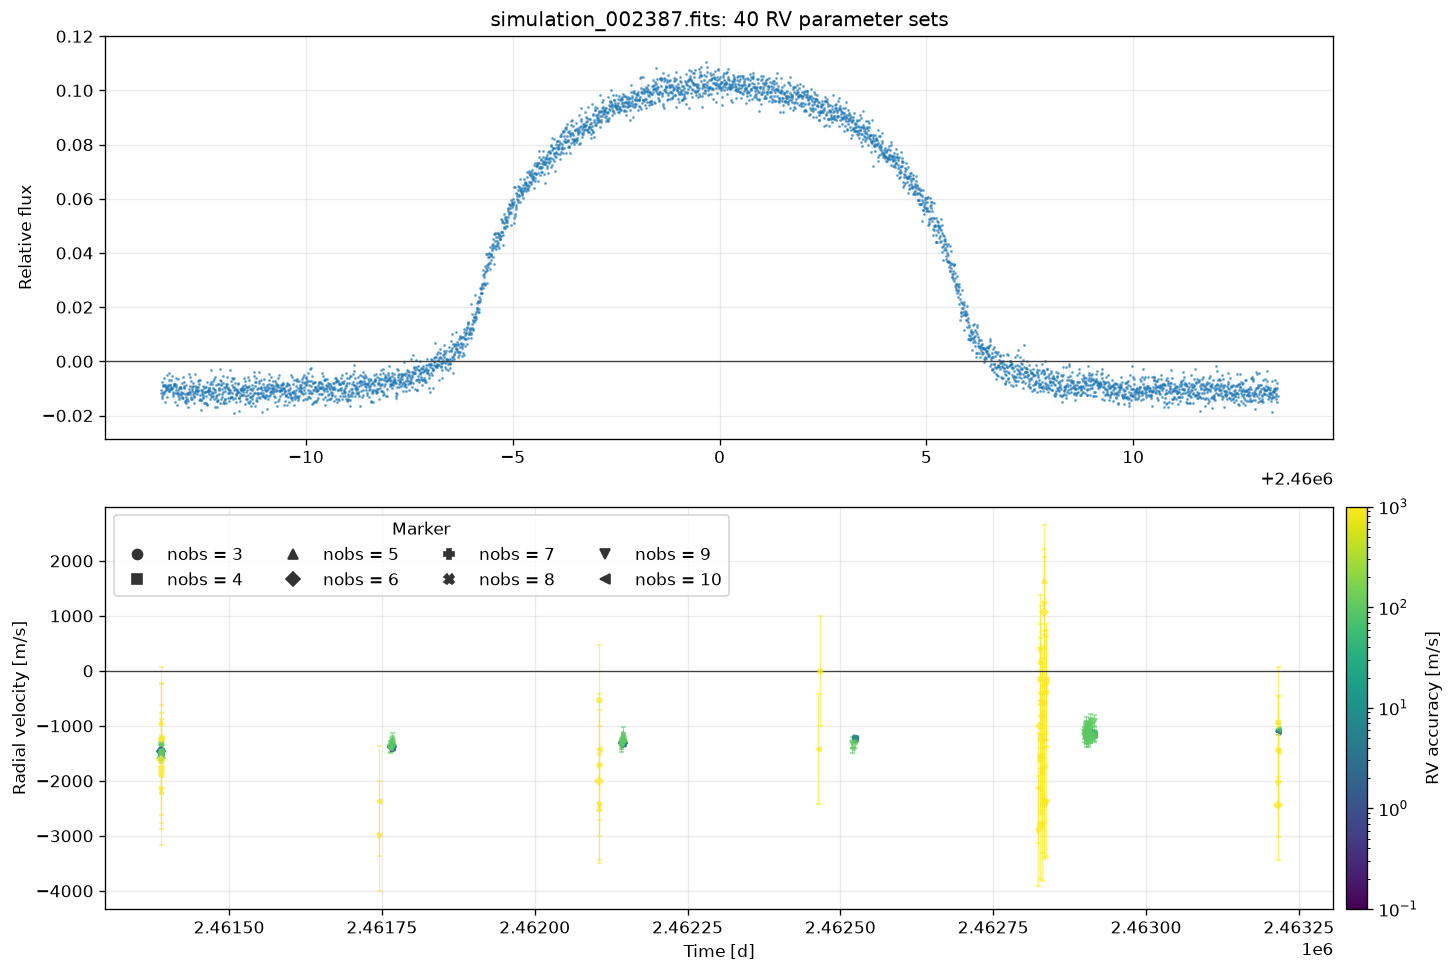

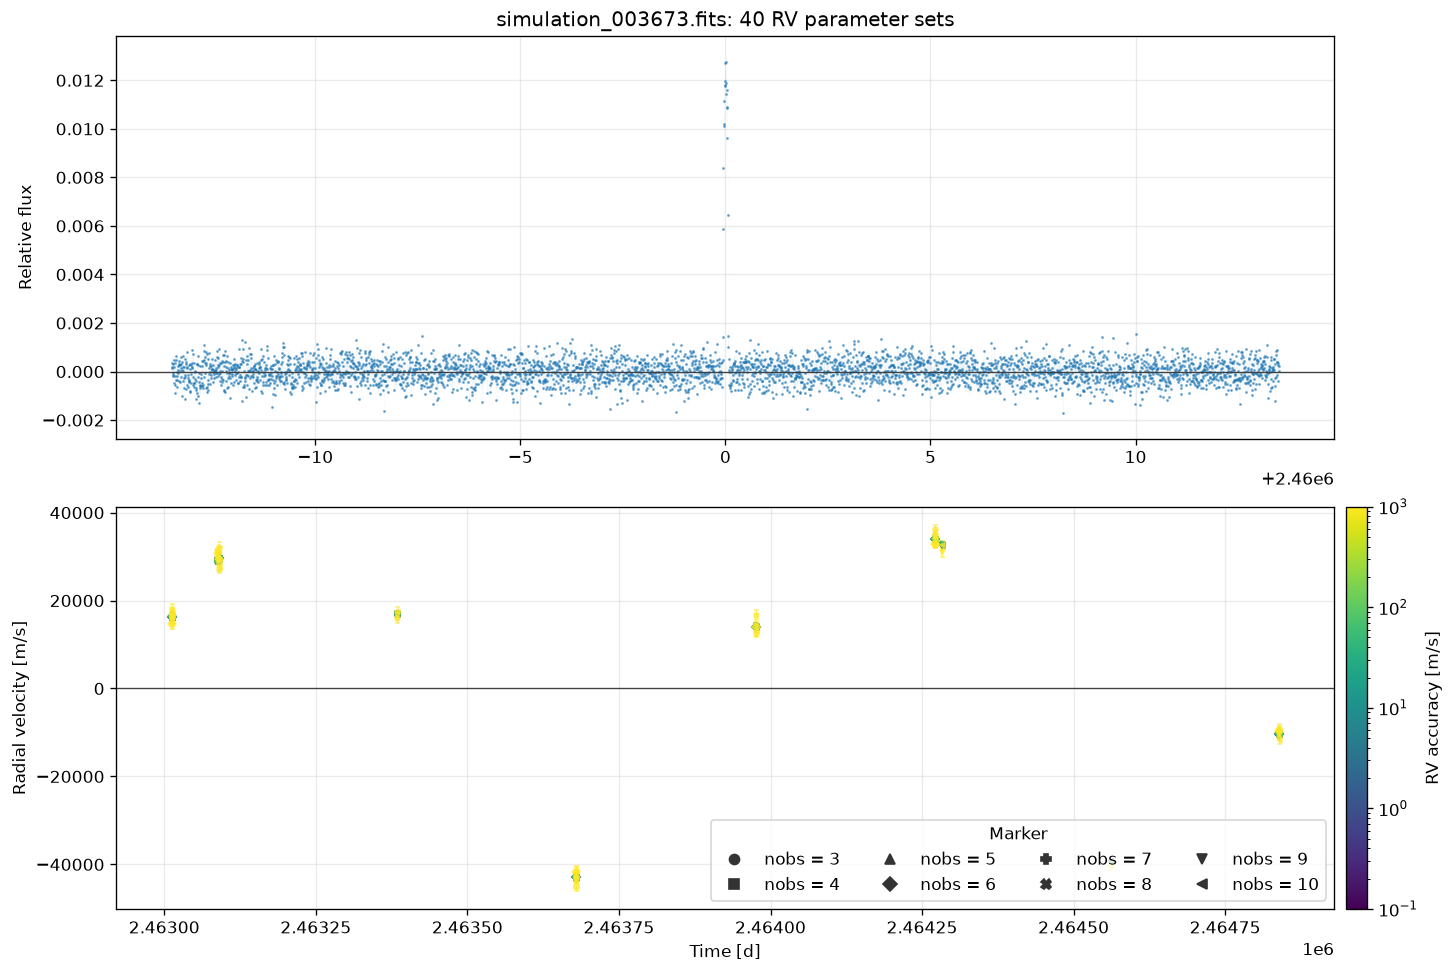

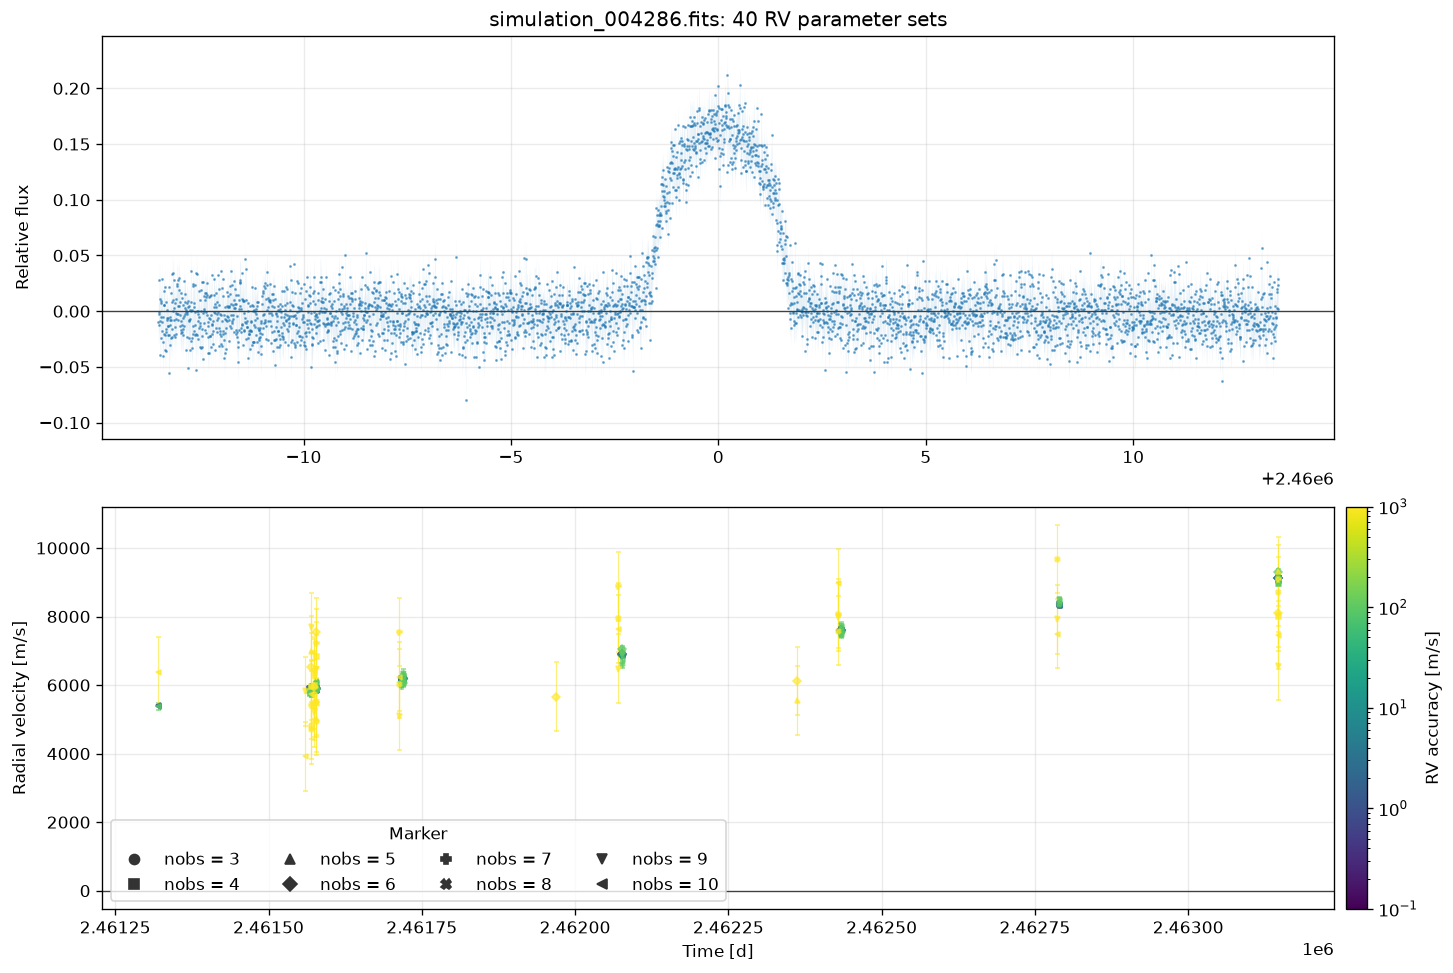

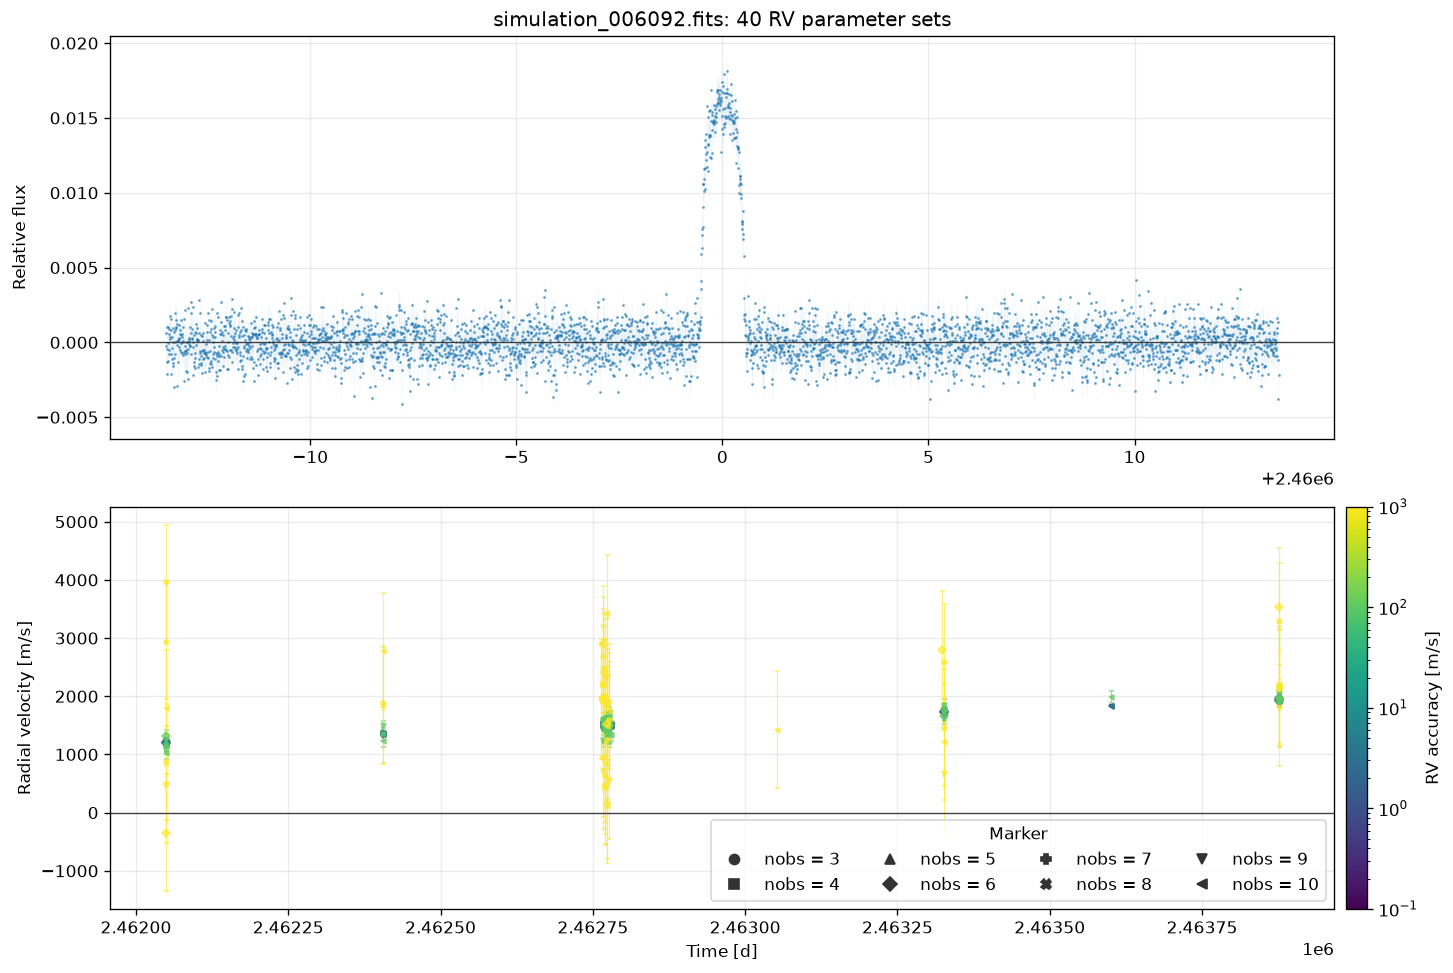

In [2]:
def finite_curve(data, time_name, *value_names):
    times = np.asarray(data[time_name], dtype=float)
    mask = np.isfinite(times)
    return (times[mask], *(np.asarray(data[name], dtype=float)[mask] for name in value_names))


def plot_system(path):
    """Plot the shared light curve and all RV extensions in one FITS file."""
    with fits.open(path, memmap=False) as hdul:
        extensions = [hdu for hdu in hdul[1:] if hdu.data is not None and 'RV_ID' in hdu.header]
        if not extensions:
            raise ValueError(f'No RV extensions found in {path}')

        lc_time, lc, lc_err = finite_curve(extensions[0].data, 'lc_time', 'lc', 'lc_err')
        accuracies = np.asarray([float(hdu.header['RV_ACC']) for hdu in extensions])
        nobs_values = sorted({int(hdu.header['NOBS']) for hdu in extensions})
        marker_cycle = ('o', 's', '^', 'D', 'P', 'X', 'v', '<', '>')
        markers = {nobs: marker_cycle[index % len(marker_cycle)] for index, nobs in enumerate(nobs_values)}
        norm = colors.LogNorm(vmin=accuracies.min(), vmax=accuracies.max())
        cmap = plt.get_cmap('viridis')

        fig, (phot_ax, rv_ax) = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
        phot_ax.plot(lc_time, lc, '.', ms=1.5, alpha=0.55, color='tab:blue')
        phot_ax.fill_between(lc_time, lc - lc_err, lc + lc_err, color='tab:blue', alpha=0.12, linewidth=0)
        phot_ax.axhline(0, color='0.25', lw=0.8)
        phot_ax.set(ylabel='Relative flux', title=f'{path.stem}: {len(extensions)} RV parameter sets')

        for hdu, accuracy in zip(extensions, accuracies):
            rv_time, rv, rv_err = finite_curve(hdu.data, 'rv_time', 'rv', 'rv_err')
            nobs = int(hdu.header['NOBS'])
            rv_ax.errorbar(
                rv_time, rv, yerr=rv_err, fmt=markers[nobs], ms=3, lw=0.7, capsize=1.5,
                color=cmap(norm(accuracy)), alpha=0.62,
            )

        rv_ax.axhline(0, color='0.25', lw=0.8)
        rv_ax.set(xlabel='Time [d]', ylabel='Radial velocity [m/s]')
        marker_handles = [
            lines.Line2D([], [], marker=markers[nobs], linestyle='', color='0.2', label=f'nobs = {nobs}')
            for nobs in nobs_values
        ]
        rv_ax.legend(handles=marker_handles, title='Marker', ncol=min(4, len(marker_handles)), loc='best')
        colourbar = fig.colorbar(
            plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=rv_ax, pad=0.01
        )
        colourbar.set_label('RV accuracy [m/s]')
        plt.show()


available_paths = rv_paths()
if not available_paths:
    raise RuntimeError('No generated RV FITS files found. Run stage 2 first.')

rng = np.random.default_rng(RANDOM_SEED)
sample_paths = rng.choice(available_paths, size=min(SAMPLE_SIZE, len(available_paths)), replace=False)
print(f'Previewing {len(sample_paths)} of {len(available_paths)} generated systems')
for path in sorted(map(Path, sample_paths)):
    plot_system(path)